© 2026 by Tamás Takács is licensed under CC BY-NC-SA 4.0. To view a copy of this license, visit https://creativecommons.org/licenses/by-nc-sa/4.0/

# **The Intake Register**

**Deep Network Development W06/A**

**Topic:** Loading a real export, coping with missing values, summary statistics, and counting categories.

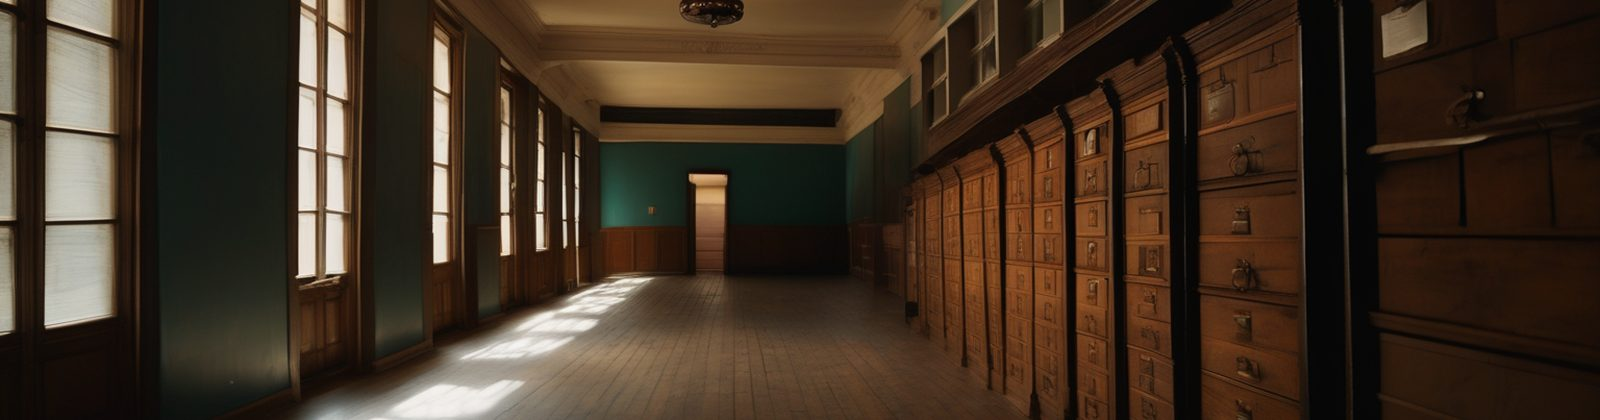

## **What this is**

`register.csv` is an export from a records system: text and numbers mixed in one file, and empty fields where a value was never recorded. Every part here has to cope with those empty fields rather than assume they are absent.

| Part | Asks for | Points |
|---|---|---:|
| a | What is missing, and how many of each category | 30 |
| b | Five summary statistics per numeric column | 35 |
| c | A numeric column averaged inside each category | 35 |

Statistics are reported **times 100, rounded to the nearest whole number**: a mean of `88.8937` is submitted as `8889`. Counts are plain integers.



## **What exactly is being asked**

`register.csv` has 9000 rows and a header. Its columns, in file order:

| column | kind |
|---|---|
| `age` | numeric, **has missing values** |
| `income` | numeric, **has missing values** |
| `tenure_months` | numeric, complete |
| `score` | numeric, **has missing values** |
| `region` | one of `North, Harbour, Midland, Eastfield, Southgate, Upland` |
| `plan` | one of `basic, standard, premium, legacy` |
| `channel` | one of `shop, phone, online` |

A missing value is an **empty field**, so a row can read `47,,22,30.6,...`. It is not a zero and it is not a blank string to be counted as a category; it is an absence.

**Part a, 17 rows.**

- rows `0..3`: how many values are **missing** in `age`, `income`, `tenure_months`, `score`, in that order.
- rows `4..16`: how many rows fall in each category level, taking `region` first (its six levels in the order listed above), then `plan` (four levels), then `channel` (three).

**Part b, 20 rows.** For each numeric column in the order `age, income, tenure_months, score`, report five statistics in this order: **mean, median, standard deviation, minimum, maximum**. Rows `0..4` are `age`, rows `5..9` are `income`, and so on.

Every statistic **ignores the missing values in that column and uses every other row**. It does not drop a row because some *other* column is missing. The standard deviation is the population one, dividing by the count rather than by the count minus one.

**Part c, 13 rows.** Three groupings, in order: `score` averaged within each `region` (6 rows), then `income` within each `plan` (4 rows), then `tenure_months` within each `channel` (3 rows). Levels come in the order listed in the table above. Missing values are skipped, as in part b.

## **Useful Links**

- [`numpy.genfromtxt`](https://numpy.org/doc/stable/reference/generated/numpy.genfromtxt.html)
- [Handling NaN](https://numpy.org/doc/stable/reference/routines.statistics.html)
- [`csv` module](https://docs.python.org/3/library/csv.html)
- [Matplotlib bar charts](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.bar.html)

## **Setup and data**

In [1]:
# ══════════════════════════════════════════════════════════
# Setup. DO NOT MODIFY.
# ══════════════════════════════════════════════════════════
import csv
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

def write_submission(filename, rows):
    """Write [(id, target), ...] as a DOCK-ready CSV.

    Every part of every exercise this semester ends with a call like this one.
    """
    with open(filename, "w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow(["id", "target"])
        for row_id, target in rows:
            writer.writerow([int(row_id), int(target)])
    print(f"wrote {filename}: {len(rows)} rows")

# Download register.csv from the exercise page on DOCK and put it next to this
# notebook (in Colab: drag it into the file browser on the left).
_path = Path("register.csv") if Path("register.csv").exists() else Path("data/register.csv")

NUMERIC = ["age", "income", "tenure_months", "score"]
CATEGORICAL = ["region", "plan", "channel"]
CATEGORIES = {
    "region": ["North", "Harbour", "Midland", "Eastfield", "Southgate", "Upland"],
    "plan": ["basic", "standard", "premium", "legacy"],
    "channel": ["shop", "phone", "online"],
}

with open(_path, newline="", encoding="utf-8") as f:
    reader = csv.DictReader(f)
    records = list(reader)

print(f"{len(records)} rows, columns: {list(records[0])}")
print("first row:", records[0])

9000 rows, columns: ['age', 'income', 'tenure_months', 'score', 'region', 'plan', 'channel']
first row: {'age': '47', 'income': '', 'tenure_months': '20', 'score': '33.8', 'region': 'Southgate', 'plan': 'legacy', 'channel': 'shop'}


## **A first look**

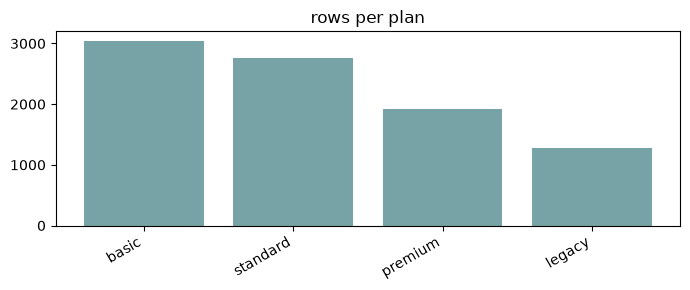

In [7]:
# ── A first look (display helper, no need to modify) ──

def bar(labels, values, title):
    plt.figure(figsize=(7, 3))
    plt.bar(range(len(values)), values, color="#78a3a6")
    plt.xticks(range(len(labels)), labels, rotation=30, ha="right")
    plt.title(title)
    plt.tight_layout()
    plt.show()

plan = np.array([r["plan"] for r in records])
counts = [int((plan == name).sum()) for name in CATEGORIES["plan"]]
bar(CATEGORIES["plan"], counts, "rows per plan")

---
## **Part a: What is in the file (30 points)**

Submission: `part1_submission.csv`, 17 rows, uploaded to part a.

In [8]:
part1 = []

# ── Your code starts here ──
row_id = 0

# rows 0..3: missing count per numeric column
for col in NUMERIC:
    values = np.array([r[col] for r in records])
    n_missing = int((values == "").sum())
    part1.append((row_id, n_missing))
    row_id += 1

# rows 4..16: row count per category level
for col in CATEGORICAL:
    values = np.array([r[col] for r in records])
    for level in CATEGORIES[col]:
        n_rows = int((values == level).sum())
        part1.append((row_id, n_rows))
        row_id += 1

write_submission("part1_submission.csv", part1)
part1

wrote part1_submission.csv: 17 rows


[(0, 542),
 (1, 823),
 (2, 0),
 (3, 361),
 (4, 2011),
 (5, 1625),
 (6, 1819),
 (7, 1239),
 (8, 1420),
 (9, 886),
 (10, 3048),
 (11, 2763),
 (12, 1915),
 (13, 1274),
 (14, 2673),
 (15, 2342),
 (16, 3985)]

---
## **Part b: Summary statistics (35 points)**

Submission: `part2_submission.csv`, 20 rows, uploaded to part b.

In [4]:
part2 = [(i, 0) for i in range(5 * 4)]

# ── Your code starts here ──
# for each numeric column: mean, median, std, min, max

write_submission("part2_submission.csv", part2)
part2[:5]

wrote part2_submission.csv: 20 rows


[(0, 0), (1, 0), (2, 0), (3, 0), (4, 0)]

---
## **Part c: Grouped averages (35 points)**

This is where the file starts to say something. Two of these three groupings show a clear pattern; one of them barely moves. Plot them before you submit and you will see which is which.

Submission: `part3_submission.csv`, 13 rows, uploaded to part c.

In [5]:
part3 = [(i, 0) for i in range(6 + 4 + 3)]

# ── Your code starts here ──
# score by region, then income by plan, then tenure_months by channel

write_submission("part3_submission.csv", part3)
part3

wrote part3_submission.csv: 13 rows


[(0, 0),
 (1, 0),
 (2, 0),
 (3, 0),
 (4, 0),
 (5, 0),
 (6, 0),
 (7, 0),
 (8, 0),
 (9, 0),
 (10, 0),
 (11, 0),
 (12, 0)]

---
## **Before you leave**

Upload each CSV to its own part on DOCK.

